### 1 · Data audit, cleaning and exploratory analysis

This stage is about checking whether our data is trustworthy, deciding which time period to study, and understanding how the Indian stock market behaves before building our models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller, acf
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
import sys; sys.path.insert(0, "..")
from src.common import INTERIM, PROC, TD, TRAIN_END, save_fig

sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
core = pd.read_csv(INTERIM / "core_close.csv", index_col="Date", parse_dates=True)
stocks = pd.read_csv(INTERIM / "stocks_close.csv", index_col="Date", parse_dates=True)
repo = pd.read_csv(INTERIM / "repo_rate.csv", index_col="Date", parse_dates=True)["repo_rate"]
print("core  :", core.shape, core.index.min().date(), "to", core.index.max().date())
print("stocks:", stocks.shape, "| repo rate:", repo.shape)


core  : (4616, 11) 2008-01-01 to 2026-10-27
stocks: (4616, 15) | repo rate: (4616,)


#### 1. Audit: coverage and gaps

adjusted the dates to match the Nifty 50 market and filled small gaps caused by different market holidays. But actual missing data still needs to be identified and handled separately.

In [2]:
audit = pd.DataFrame({"first valid date": core.apply(lambda s: s.first_valid_index().date()),
                      "last valid date": core.apply(lambda s: s.last_valid_index().date()),
                      "missing days": core.isna().sum(),
                      "missing after India VIX starts": core.loc[core["india_vix"].first_valid_index():].isna().sum()})
display(audit)
print("Stock basket missing cells:", int(stocks.isna().sum().sum()))

,first valid date,last valid date,missing days,missing after India VIX starts
nifty50,2008-01-01,2026-10-27,0,0
sensex,2008-01-02,2026-10-27,1,0
banknifty,2008-01-01,2026-10-27,0,0
nifty_it,2008-01-01,2026-10-27,0,0
india_vix,2008-03-03,2026-10-27,44,0
usdinr,2008-01-01,2026-10-27,13,13
brent,2008-01-02,2026-10-27,9,8
gold,2008-01-02,2026-10-27,1,0
sp500,2008-01-02,2026-10-27,1,0
us10y,2008-01-02,2026-10-27,1,0


Stock basket missing cells: 0


We chose March 2008 as the starting point so that all important indicators can be studied together without losing the historical market crisis data.

In [3]:
START = core["india_vix"].first_valid_index()
core, stocks, repo = core.loc[START:].copy(), stocks.loc[START:].copy(), repo.loc[START:]
print("Sample starts", START.date(), "|", len(core), "trading days")
gaps = {c: core[c][core[c].isna()].index for c in core if core[c].isna().any()}
for c, idx in gaps.items():
    print(f"{c}: {len(idx)} missing days, {idx.min().date()} to {idx.max().date()}")

Sample starts 2008-03-03 | 4572 trading days
usdinr: 13 missing days, 2008-08-06 to 2008-08-25
brent: 8 missing days, 2009-04-20 to 2009-04-29


#### 2. cleaning

We filled genuine missing data using the last known price and corrected suspicious one-day price errors, while making sure that real market crashes were not removed.

In [4]:
log = []
for c in gaps:
    for d in gaps[c]:
        log.append({"Date": d.date(), "series": c, "problem": "missing in source (gap > 3 days)", "old value": np.nan})
core = core.ffill()
for c, idx in gaps.items():
    for row in log:
        if row["series"] == c and pd.Timestamp(row["Date"]) in idx:
            row["new value"] = core.at[pd.Timestamp(row["Date"]), c]

def find_glitches(s):
    """Days whose price is a spike: far from its neighbours' median, or a huge move that immediately reverses."""
    r = np.log(s).diff()
    vol = r.rolling(63, min_periods=20).std().shift(1)
    spike_revert = (r.abs() > 6 * vol) & ((r + r.shift(-1)).abs() < 0.3 * r.abs())
    med_dev = (s / s.rolling(5, center=True, min_periods=3).median() - 1).abs() > 0.03
    # the median rule is meant for slow-moving series (currencies, dollar index); equity indices legitimately move > 3%
    return spike_revert | (med_dev if s.name in ("usdinr", "dxy") else False)

# fix one glitch at a time and re-check: a genuine price squeezed between two glitches must not be flagged by them
for c in core:
    while True:
        f = find_glitches(core[c].rename(c))
        if not f.any():
            break
        d = f.index[f][0]                                   # earliest remaining glitch of this series
        old = core.at[d, c]
        core.at[d, c] = core[c].shift(1).at[d]              # previous day's price
        log.append({"Date": d.date(), "series": c, "problem": "glitch tick (spike that reverses)", "old value": old, "new value": core.at[d, c]})
for row in log:
    if pd.isna(row.get("new value", np.nan)):
        row["new value"] = core.at[pd.Timestamp(row["Date"]), row["series"]]
cleaning_log = pd.DataFrame(log).sort_values(["series", "Date"])
display(cleaning_log[cleaning_log["problem"].str.startswith("glitch")])
print("Total fixes logged:", len(cleaning_log), "| missing values left:", int(core.isna().sum().sum()))
assert core.notna().all().all() and stocks.notna().all().all()

,Date,series,problem,old value,new value
21,2012-01-27,usdinr,glitch tick (spike that reverses),52.493000,50.000000
22,2012-01-31,usdinr,glitch tick (spike that reverses),52.493000,49.388000
23,2013-09-04,usdinr,glitch tick (spike that reverses),68.610001,66.510002
24,2023-11-02,usdinr,glitch tick (spike that reverses),85.194000,83.277199
25,2023-12-29,usdinr,glitch tick (spike that reverses),82.302002,83.267197


Total fixes logged: 26 | missing values left: 0


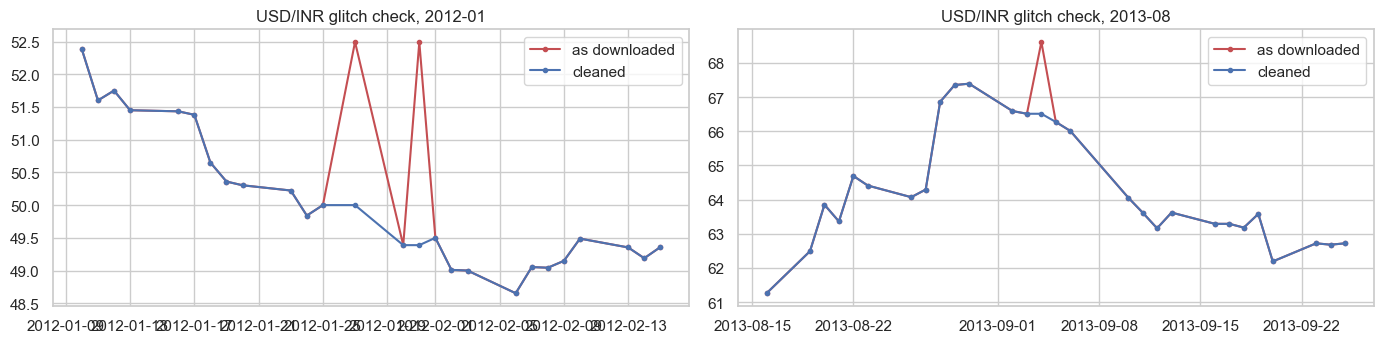

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
raw_fx = pd.read_csv(INTERIM / "core_close.csv", index_col="Date", parse_dates=True)["usdinr"]
for a, (lo, hi) in zip(ax, [("2012-01-10", "2012-02-15"), ("2013-08-15", "2013-09-25")]):
    a.plot(raw_fx.loc[lo:hi], "o-", color="#c44e52", ms=3, label="as downloaded")
    a.plot(core["usdinr"].loc[lo:hi], "o-", color="#4c72b0", ms=3, label="cleaned")
    a.set_title(f"USD/INR glitch check, {lo[:7]}"); a.legend()
save_fig(fig, "eda_cleaning_fx"); plt.show()

#### Returns and the enrichments table
We calculate daily price changes using log returns and add RBI interest-rate data to understand how monetary policy affects market conditions and investment performance.

In [6]:
returns = np.log(core).diff().iloc[1:]
stock_returns = np.log(stocks).diff().iloc[1:]
macro = pd.DataFrame({"repo_rate": repo, "repo_change_63d": repo.diff(63), "risk_free_daily": repo / 100 / TD})
core.to_csv(PROC / "clean.csv", index_label="Date")
returns.to_csv(PROC / "returns.csv", index_label="Date")
stocks.to_csv(PROC / "stocks_clean.csv", index_label="Date")
macro.to_csv(PROC / "macro.csv", index_label="Date")
cleaning_log.to_csv(PROC / "cleaning_log.csv", index=False)
print("Saved clean.csv", core.shape, "| returns.csv", returns.shape, "| stocks_clean.csv", stocks.shape, "| macro.csv", macro.shape)
print("Train period:", core.index.min().date(), "to", core.loc[:TRAIN_END].index.max().date(), f"({(core.index <= TRAIN_END).sum()} days)",
      "| test period:", core.loc[TRAIN_END:].index.min().date(), "to", core.index.max().date(), f"({(core.index > TRAIN_END).sum()} days)")

Saved clean.csv (4572, 11) | returns.csv (4571, 11) | stocks_clean.csv (4572, 15) | macro.csv (4572, 3)
Train period: 2008-03-03 to 2017-12-29 (2399 days) | test period: 2018-01-02 to 2026-10-27 (2173 days)


### Exploratory analysis

#### 4.1 Prices and the main stress episodes

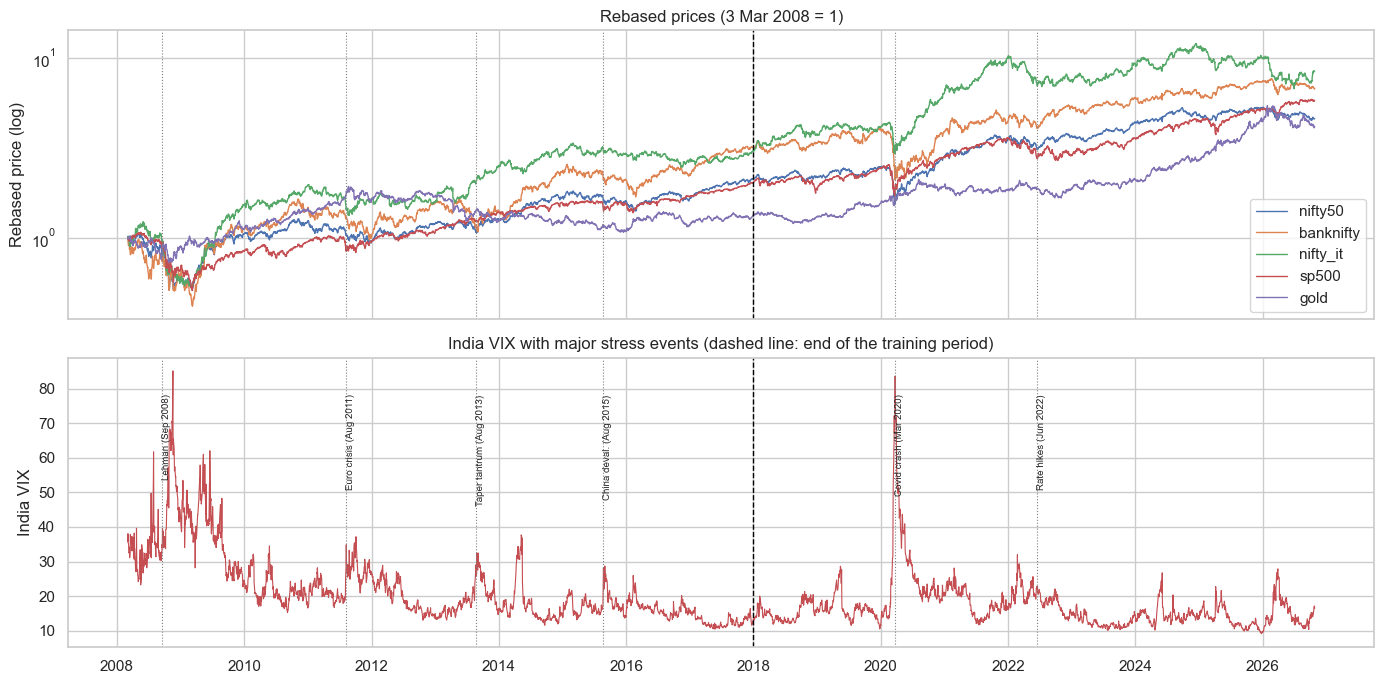

In [7]:
EVENTS = {"Lehman (Sep 2008)": "2008-09-15", "Euro crisis (Aug 2011)": "2011-08-05", "Taper tantrum (Aug 2013)": "2013-08-20",
          "China deval. (Aug 2015)": "2015-08-24", "Covid crash (Mar 2020)": "2020-03-23", "Rate hikes (Jun 2022)": "2022-06-17"}
fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
rebased = core[["nifty50", "banknifty", "nifty_it", "sp500", "gold"]] / core[["nifty50", "banknifty", "nifty_it", "sp500", "gold"]].iloc[0]
rebased.plot(ax=ax[0], logy=True, lw=1); ax[0].set_ylabel("Rebased price (log)"); ax[0].set_title("Rebased prices (3 Mar 2008 = 1)")
ax[1].plot(core["india_vix"], color="#c44e52", lw=.8); ax[1].set_ylabel("India VIX")
for a in ax:
    a.axvline(TRAIN_END, color="black", ls="--", lw=1)
    for name, d in EVENTS.items():
        a.axvline(pd.Timestamp(d), color="grey", ls=":", lw=.8)
for name, d in EVENTS.items():
    ax[1].text(pd.Timestamp(d), core["india_vix"].max() * .92, name, rotation=90, fontsize=7, va="top")
ax[1].set_title("India VIX with major stress events (dashed line: end of the training period)")
save_fig(fig, "eda_prices_vix"); plt.show()

#### 4.2 Distribution of returns : fat tails

,mean % (ann.),volatility % (ann.),skewness,excess kurtosis,min daily %,max daily %,Jarque-Bera p
nifty50,8.405,19.841,-0.268,16.593,-13.904,16.334,0.0
sensex,8.184,20.076,-0.194,15.488,-14.102,15.990,0.0
banknifty,10.492,26.686,-0.190,10.290,-18.313,17.239,0.0
nifty_it,11.743,24.301,-0.226,6.148,-12.490,11.720,0.0
india_vix,-4.298,92.378,0.563,9.195,-47.020,50.456,0.0
usdinr,4.745,7.450,0.199,5.736,-3.761,3.915,0.0
brent,0.690,39.378,-0.422,16.551,-27.976,32.117,0.0
gold,7.847,18.757,-0.424,6.944,-11.406,8.643,0.0
sp500,9.692,19.949,-0.456,13.514,-12.765,10.957,0.0
us10y,1.905,43.861,0.831,40.770,-34.701,49.670,0.0


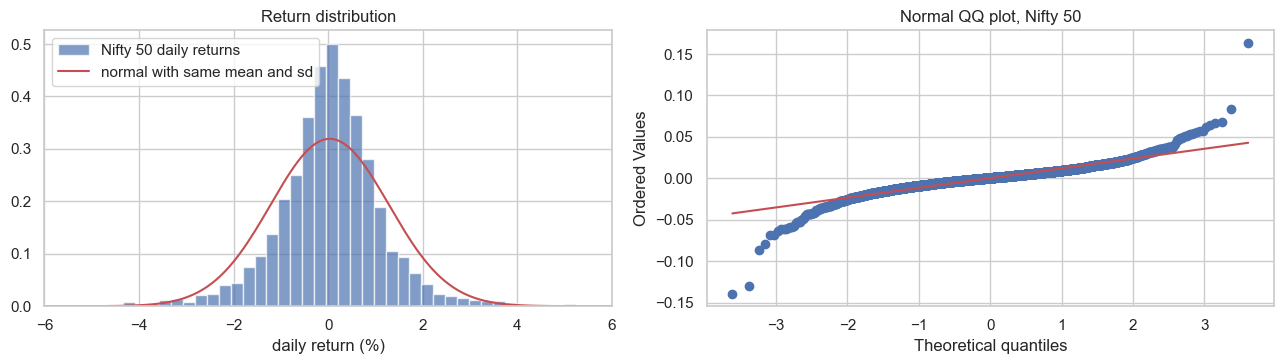

In [8]:
summary = pd.DataFrame({"mean % (ann.)": returns.mean() * TD * 100, "volatility % (ann.)": returns.std() * np.sqrt(TD) * 100,
                        "skewness": returns.skew(), "excess kurtosis": returns.kurt(),
                        "min daily %": returns.min() * 100, "max daily %": returns.max() * 100,
                        "Jarque-Bera p": returns.apply(lambda x: stats.jarque_bera(x).pvalue)})
display(summary.round(3))
r = returns["nifty50"]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(r * 100, bins=120, density=True, color="#4c72b0", alpha=.7, label="Nifty 50 daily returns")
xs = np.linspace(r.min(), r.max(), 400)
ax[0].plot(xs * 100, stats.norm.pdf(xs, r.mean(), r.std()) / 100, color="#c44e52", label="normal with same mean and sd")
ax[0].set_xlim(-6, 6); ax[0].set_xlabel("daily return (%)"); ax[0].legend(); ax[0].set_title("Return distribution")
stats.probplot(r, dist="norm", plot=ax[1]); ax[1].set_title("Normal QQ plot, Nifty 50")
save_fig(fig, "eda_return_distribution"); plt.show()

#### 4.3 Volatility clustering and stationarity


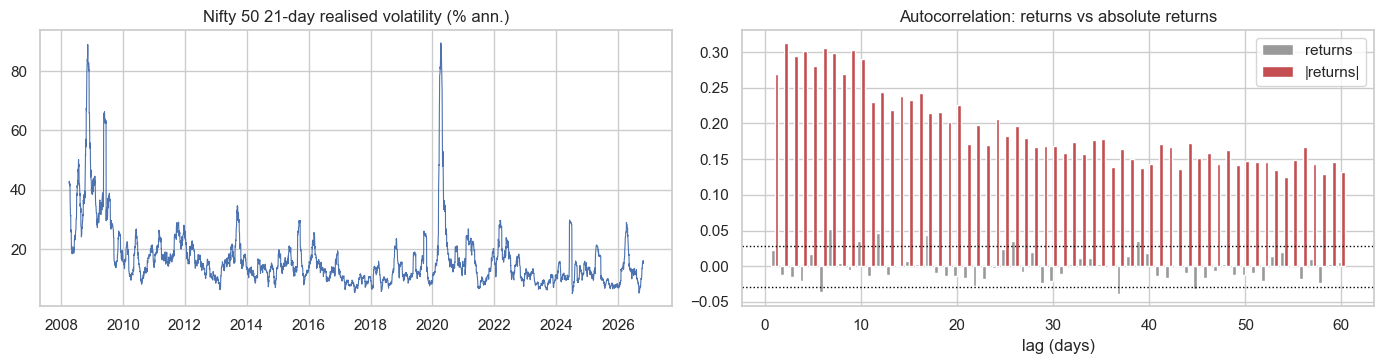

,"ADF p-value, price level","ADF p-value, log return"
nifty50,0.8562,0.0
sensex,0.8720,0.0
banknifty,0.7230,0.0
nifty_it,0.6749,0.0
india_vix,0.0029,0.0
usdinr,0.6089,0.0
brent,0.0388,0.0
gold,0.9771,0.0
sp500,0.9845,0.0
us10y,0.3209,0.0


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
vol21 = r.rolling(21).std() * np.sqrt(TD) * 100
ax[0].plot(vol21, color="#4c72b0", lw=.8); ax[0].set_title("Nifty 50 21-day realised volatility (% ann.)")
lags = np.arange(1, 61)
ax[1].bar(lags - .2, acf(r, nlags=60)[1:], .4, label="returns", color="#999999")
ax[1].bar(lags + .2, acf(r.abs(), nlags=60)[1:], .4, label="|returns|", color="#c44e52")
ax[1].axhline(1.96 / np.sqrt(len(r)), color="black", ls=":", lw=1); ax[1].axhline(-1.96 / np.sqrt(len(r)), color="black", ls=":", lw=1)
ax[1].set_title("Autocorrelation: returns vs absolute returns"); ax[1].set_xlabel("lag (days)"); ax[1].legend()
save_fig(fig, "eda_volatility_clustering"); plt.show()

adf = pd.DataFrame({"ADF p-value, price level": [adfuller(np.log(core[c]).dropna(), autolag="AIC")[1] for c in core],
                    "ADF p-value, log return": [adfuller(returns[c], autolag="AIC")[1] for c in returns]}, index=core.columns)
display(adf.round(4))

#### 4.4 Correlation between markets, and how it changes in stress

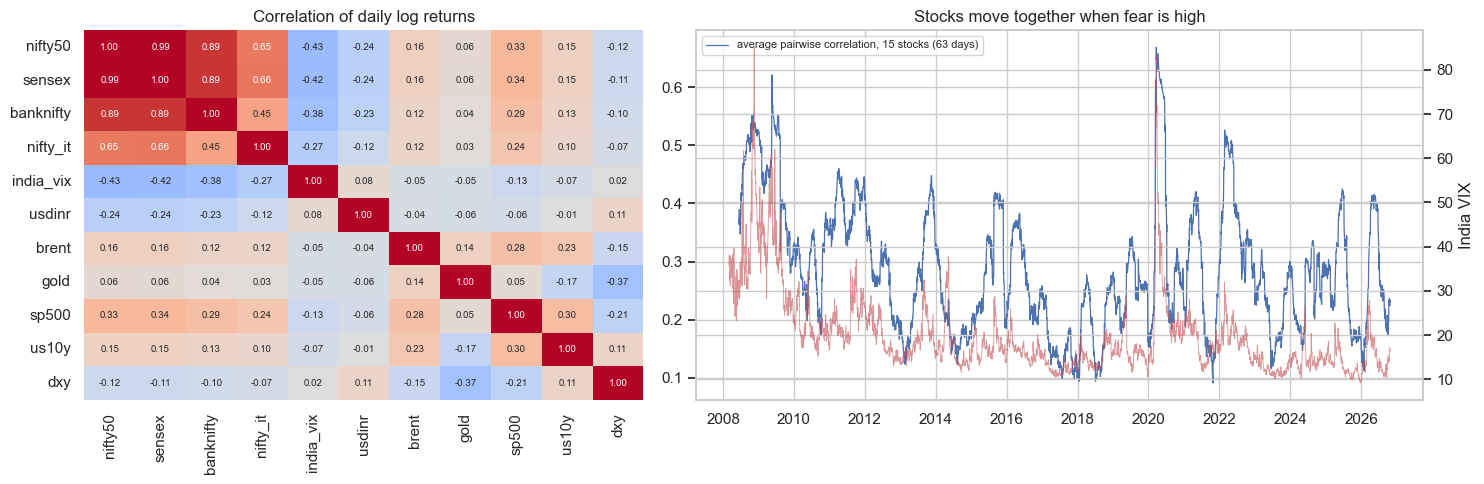

Correlation between the 63-day average stock correlation and India VIX: 0.707


In [10]:
corr = returns.corr()
avg_corr = stock_returns.rolling(63).corr().groupby(level=0).apply(lambda m: m.values[np.triu_indices(m.shape[0], 1)].mean())
fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.3]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[0], cbar=False, annot_kws={"size": 7}); ax[0].set_title("Correlation of daily log returns")
ax[1].plot(avg_corr, color="#4c72b0", lw=.9, label="average pairwise correlation, 15 stocks (63 days)")
ax2 = ax[1].twinx(); ax2.plot(core["india_vix"], color="#c44e52", lw=.6, alpha=.6, label="India VIX"); ax2.set_ylabel("India VIX")
ax[1].set_title("Stocks move together when fear is high"); ax[1].legend(loc="upper left", fontsize=8)
save_fig(fig, "eda_correlation"); plt.show()
print("Correlation between the 63-day average stock correlation and India VIX:", round(avg_corr.corr(core["india_vix"].reindex(avg_corr.index)), 3))

#### Summary 
1. Dataset: Prepared 11 market indicators and 15 major stocks, covering 2008–2026, with RBI repo-rate data.

2. Data cleaning: Fixed missing values and suspicious USD/INR price spikes while preserving genuine market crashes.

3. Fat tails: Found that extreme market movements are more common than a normal distribution predicts, so historical simulation will be used for VaR.

4. Volatility clustering: High- and low-volatility periods tend to persist, supporting the idea of market regimes.

5. Stationarity: Returns are more suitable for modelling than raw stock prices.

6. Correlation: Stocks tend to move together during market stress, reducing diversification benefits. Average stock correlation is therefore included as a potential model feature.

Overall: The analysis confirms that market behaviour changes over time, providing a strong foundation for building market regime detection and risk-management models.